In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Innlastning av dataset #

In [2]:
df_movie_metadata = pd.read_csv('data/movies_metadata.csv')
df_movie_metadata.head()

C:\Users\Didrik\AppData\Local\Temp\ipykernel_15908\2514860032.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df_movie_metadata = pd.read_csv('data/movies_metadata.csv')


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


In [3]:
df_credits = pd.read_csv('data/credits.csv')
df_credits.head()

,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


In [4]:
df_keywords = pd.read_csv('data/keywords.csv')
df_keywords.head()

,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


In [5]:
df_links_small = pd.read_csv('data/links_small.csv')
df_links_small.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [6]:
df_links = pd.read_csv('data/links.csv')
df_links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


In [7]:
df_ratings_small = pd.read_csv('data/ratings_small.csv')
df_ratings_small.head()

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


In [8]:
df_ratings = pd.read_csv('data/ratings.csv')
df_ratings.head()

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


-------------------------------------------------

# Utforskning av data #
Utforsker de ulike csv-filene ved hjelp av .shape, .head(), .dtypes og .info(), og går deretter videre med manglende verdier, duplikater og fordelinger per fil.

Del A (movies_metadata, credits, keywords) og del B (links og ratings) er skrevet hver for seg og kan kjøres uavhengig av hverandre.

# Del A: Movies_metadata, Credits og Keywords #

## Movies_metadata ##

### 1. Oversikt over metadata

#### Antall rader og kolonner (`shape`)

In [217]:
df_movie_metadata.shape

(45466, 24)

#### Eksempelrader (`head`)

In [218]:
df_movie_metadata[["id", "title", "release_date", "runtime", "revenue"]].head()

,id,title,release_date,runtime,revenue
0,862,Toy Story,1995-10-30,81.00,"373,554,033.00"
1,8844,Jumanji,1995-12-15,104.00,"262,797,249.00"
2,15602,Grumpier Old Men,1995-12-22,101.00,0.00
3,31357,Waiting to Exhale,1995-12-22,127.00,"81,452,156.00"
4,11862,Father of the Bride Part II,1995-02-10,106.00,"76,578,911.00"


#### Datatyper (`dtypes`)

In [219]:
df_movie_metadata.dtypes

adult                        str
belongs_to_collection        str
budget                       str
genres                       str
homepage                     str
id                           str
imdb_id                      str
original_language            str
original_title               str
overview                     str
popularity                object
poster_path                  str
production_companies         str
production_countries         str
release_date                 str
revenue                  float64
runtime                  float64
spoken_languages             str
status                       str
tagline                      str
title                        str
video                     object
vote_average             float64
vote_count               float64
dtype: object

#### Datasettinformasjon (`info`)

In [220]:
df_movie_metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  str    
 1   belongs_to_collection  4494 non-null   str    
 2   budget                 45466 non-null  str    
 3   genres                 45466 non-null  str    
 4   homepage               7782 non-null   str    
 5   id                     45466 non-null  str    
 6   imdb_id                45449 non-null  str    
 7   original_language      45455 non-null  str    
 8   original_title         45466 non-null  str    
 9   overview               44512 non-null  str    
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  str    
 12  production_companies   45463 non-null  str    
 13  production_countries   45463 non-null  str    
 14  release_date           45379 non-null  str    
 15  revenue      

### 2. Manglende verdier før rensing

In [221]:
df_movie_metadata.isna().sum()

adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   5
poster_path                386
production_companies         3
production_countries         3
release_date                87
revenue                      6
runtime                    263
spoken_languages             6
status                      87
tagline                  25054
title                        6
video                        6
vote_average                 6
vote_count                   6
dtype: int64

### 3. Undersøkelse og fjerning av feilformaterte rader

In [222]:
print("Rader uten tittel:", df_movie_metadata["title"].isna().sum())

Rader uten tittel: 6


In [223]:
df_movie_metadata.loc[
    df_movie_metadata["title"].isna(),
    ["id", "original_title", "release_date", "revenue",
     "runtime", "vote_average", "vote_count"]
]

,id,original_title,release_date,revenue,runtime,vote_average,vote_count
19729,82663,Midnight Man,NaN,NaN,NaN,NaN,NaN
19730,1997-08-20,"[{'iso_639_1': 'en', 'name': 'English'}]",1,NaN,NaN,NaN,NaN
29502,122662,マルドゥック・スクランブル 排気,NaN,NaN,NaN,NaN,NaN
29503,2012-09-29,"[{'iso_639_1': 'ja', 'name': '日本語'}]",12,NaN,NaN,NaN,NaN
35586,249260,Avalanche Sharks,NaN,NaN,NaN,NaN,NaN
35587,2014-01-01,"[{'iso_639_1': 'en', 'name': 'English'}]",22,NaN,NaN,NaN,NaN


Det observeres seks rader uten title. De kommer i tre par: første rad har filmens ID, originaltittel og starten av overview, mens neste rad har resten av overview og de resterende feltene forskjøvet. I rå CSV har radene henholdsvis 10 og 15 felt, i stedet for 24. Dette er tre splittede filmoppføringer, ikke seks filmer som må slettes.

Hvert par slås sammen: fortsettelsen av overview legges til teksten, og de siste 14 feltene flyttes tilbake til riktige kolonner. Ingen nye filmopplysninger gjettes. Råfilen beholdes urørt.

In [224]:
import csv

with open("data/movies_metadata.csv", newline="", encoding="utf-8") as fil:
    leser = csv.reader(fil)
    kolonnenavn = next(leser)
    rader = list(leser)

reparerte_rader = []
for indeks in [19729, 29502, 35586]:
    start = rader[indeks]
    fortsettelse = rader[indeks + 1]
    assert len(start) == 10 and len(fortsettelse) == 15
    samlet = start[:9] + [start[9] + fortsettelse[0]] + fortsettelse[1:]
    assert len(samlet) == len(kolonnenavn)
    reparerte_rader.append(samlet)

reparert = pd.DataFrame(
    reparerte_rader, columns=kolonnenavn, index=[19729, 29502, 35586]
).replace("", np.nan)

# Disse fire kolonnene var allerede tall i den opprinnelige DataFramen.
for kolonne in ["revenue", "runtime", "vote_average", "vote_count"]:
    reparert[kolonne] = pd.to_numeric(reparert[kolonne])

df_movie_metadata = df_movie_metadata.drop(index=[19729, 19730, 29502, 29503, 35586, 35587])
df_movie_metadata = pd.concat([df_movie_metadata, reparert]).sort_index()

reparert[["id", "title", "release_date", "runtime", "vote_count"]]

,id,title,release_date,runtime,vote_count
19729,82663,Midnight Man,1997-08-20,104.00,1
29502,122662,Mardock Scramble: The Third Exhaust,2012-09-29,68.00,12
35586,249260,Avalanche Sharks,2014-01-01,82.00,22


Observasjon etter reparasjonen: Midnight Man, Mardock Scramble: The Third Exhaust og Avalanche Sharks har nå tittel, gyldig utgivelsesdato og spilletid på henholdsvis 104, 68 og 82 minutter. Antall rader går fra 45 466 til 45 463 fordi seks delrader erstattes av tre komplette oppføringer.

### 4. Gjenstående manglende verdier

In [225]:
df_movie_metadata.isna().sum()

adult                        0
belongs_to_collection    40972
budget                       0
genres                       0
homepage                 37684
id                           0
imdb_id                     17
original_language           11
original_title               0
overview                   954
popularity                   0
poster_path                383
production_companies         0
production_countries         0
release_date                84
revenue                      0
runtime                    257
spoken_languages             0
status                      81
tagline                  25050
title                        0
video                        0
vote_average                 0
vote_count                   0
dtype: int64

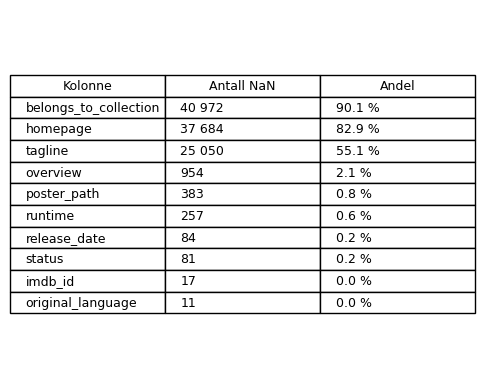

In [18]:
# Tabell over manglende verdier (NaN) etter reparasjonen, lagret som figur til rapporten
import os
os.makedirs("claude_output/figures", exist_ok=True)

manglende = df_movie_metadata.isna().sum()
manglende = manglende[manglende > 0].sort_values(ascending=False)
rader = [[kolonne, f"{antall:,}".replace(",", " "), f"{antall / len(df_movie_metadata) * 100:.1f} %"]
         for kolonne, antall in manglende.items()]

fig, ax = plt.subplots(figsize=(6, 0.4 * len(rader) + 0.8))
ax.axis("off")
tabell = ax.table(cellText=rader, colLabels=["Kolonne", "Antall NaN", "Andel"], loc="center", cellLoc="left")
tabell.auto_set_font_size(False)
tabell.set_fontsize(9)
tabell.scale(1, 1.3)
plt.savefig("claude_output/figures/eda_tabell_manglende.png", dpi=200, bbox_inches="tight")
plt.show()

### 5. Manglende utgivelsesdato

In [226]:
df_movie_metadata.loc[
    df_movie_metadata["release_date"].isna(),
    ["id", "title", "release_date", "runtime", "revenue"]
].head(5)

,id,title,release_date,runtime,revenue
711,365371,War Stories Our Mother Never Told Us,NaN,95.00,0.00
734,215107,Vermont Is for Lovers,NaN,88.00,0.00
3460,94214,"Jails, Hospitals & Hip-Hop",NaN,90.00,10.00
3628,207731,Boricua's Bond,NaN,105.00,0.00
5879,99885,Divine Intervention,NaN,87.00,0.00


Etter reparasjonen mangler 84 rader utgivelsesdato. Eksempelradene har fortsatt tittel og andre opplysninger, som spilletid. Radene beholdes fordi ukjent dato alene ikke gjør resten av filmen ugyldig. Dato imputeres ikke: et gjettet år kan plassere filmen i feil tiår. I år- og tiårsberegninger brukes bare filmer med kjent dato. Dette er en regel for de senere analysene; radene slettes ikke her.

### 6. Manglende eller null spilletid

In [227]:
print("Antall manglende spilletider:", df_movie_metadata["runtime"].isna().sum())

df_movie_metadata.loc[
    df_movie_metadata["runtime"].isna(),
    ["id", "title", "runtime", "release_date"]
].head(5)

Antall manglende spilletider: 257


,id,title,runtime,release_date
634,287305,Peanuts – Die Bank zahlt alles,NaN,1996-03-21
635,339428,Happy Weekend,NaN,1996-03-14
644,278978,Und keiner weint mir nach,NaN,1996-02-29
802,282919,Diebinnen,NaN,1996-06-20
863,253632,Baton Rouge,NaN,1988-10-08


In [228]:
(df_movie_metadata["runtime"] == 0).sum()

np.int64(1558)

Det observeres 257 manglende spilletider og 1 558 verdier lik 0. Flere filmer med manglende spilletid har kjent tittel og dato, og derfor beholdes filmoppføringene. Null minutter behandles som ukjent spilletid, ikke som en reell varighet. I spilletidsberegninger brukes bare runtime > 0. Gjennomsnitt eller median brukes ikke til imputering, fordi det ville legge konstruerte verdier inn i medianberegningen i Part 2. Denne filtreringen skal gjøres i analysen, og er ikke utført på hele DataFramen.

### 7. Manglende overview og tagline

In [229]:
df_movie_metadata[["overview", "tagline"]].isna().all(axis=1).sum()

np.int64(946)

946 filmer mangler både overview og tagline. Disse filmene beholdes fordi de fortsatt kan ha nyttig informasjon til andre analyser. Manglende tekst imputeres ikke. Filmene vil ikke gi treff i tekstsøket i oppgave 7, noe som er en begrensning ved analysen.

#### Andre manglende felt
Etter reparasjonen mangler belongs_to_collection i 40 972 rader. Dette feltet er valgfritt: en manglende verdi kan bety at filmen ikke tilhører en registrert filmserie. Det er ikke grunnlag for å fylle inn en serie.

homepage (37 684), poster_path (383) og imdb_id (17) beholdes som ukjente opplysninger. Manglende IMDb-ID i dette datasettet beviser ikke at filmen ikke finnes på IMDb; koblingene til de andre CSV-filene bruker TMDB-ID.

original_language mangler for 11 filmer. Ukjent språk er ikke det samme som et annet språk enn engelsk. Disse filmene utelates fra språkberegningen i oppgave 9. status mangler for 81 filmer og imputeres ikke til Released uten belegg.

Tallene her gjelder etter reparasjon og før fjerning av identiske rader.

### 8. Datatyper
Dtypes-outputen i del 1 viser at revenue, runtime, vote_average og vote_count er allerede tall. id og budget er tekst, popularity har blandede typer, og release_date er tekst. Eksempelverdiene under undersøkes før konvertering.

In [230]:
df_movie_metadata[["id", "budget", "popularity", "release_date"]].head(5)

,id,budget,popularity,release_date
0,862,30000000,21.95,1995-10-30
1,8844,65000000,17.02,1995-12-15
2,15602,0,11.71,1995-12-22
3,31357,16000000,3.86,1995-12-22
4,11862,0,8.39,1995-02-10


Bare id, budget, popularity og release_date konverteres. Feilformaterte tall eller datoer gir feilmelding fremfor å bli skjult som NaN. Konverteringen skjer før sammenligning av duplikater: tallet 1.5 og teksten "1.5" skal ikke gjøre ellers identiske rader forskjellige.

In [231]:
df_movie_metadata["id"] = pd.to_numeric(df_movie_metadata["id"])
df_movie_metadata["budget"] = pd.to_numeric(df_movie_metadata["budget"])
df_movie_metadata["popularity"] = pd.to_numeric(df_movie_metadata["popularity"])
df_movie_metadata["release_date"] = pd.to_datetime(
    df_movie_metadata["release_date"], format="%Y-%m-%d"
)

genres, production_companies, production_countries, spoken_languages og belongs_to_collection inneholder lister eller dictionaries lagret som tekst. De beholdes som tekst i denne delen og må parses før innsetting i MongoDB.

Konverteringen kjører uten feil etter reparasjonen. Det viser at de utfylte verdiene kan tolkes som tall og datoer, men bekrefter ikke at alle beløp eller datoer er faktuelt riktige. De manglende datoene forblir manglende.

### 9. ID-er og duplikater

In [232]:
print("Helt identiske rader:", df_movie_metadata.duplicated().sum())
print("Duplikate film-ID-er:", df_movie_metadata["id"].duplicated().sum())

Helt identiske rader: 17
Duplikate film-ID-er: 30


In [233]:
duplikater = df_movie_metadata[df_movie_metadata["id"].duplicated(keep=False)]
display(duplikater.sort_values("id")[["id", "title", "release_date", "revenue", "runtime"]].head(6))

,id,title,release_date,revenue,runtime
33826,4912,Confessions of a Dangerous Mind,2002-12-30,"33,013,805.00",113.00
5865,4912,Confessions of a Dangerous Mind,2002-12-30,"33,013,805.00",113.00
9165,5511,Le Samouraï,1967-10-25,"39,481.00",105.00
7345,5511,Le Samouraï,1967-10-25,"39,481.00",105.00
44821,10991,Pokémon: Spell of the Unknown,2000-07-08,"68,411,275.00",93.00
4114,10991,Pokémon: Spell of the Unknown,2000-07-08,"68,411,275.00",93.00


Etter lik typekonvertering observeres 17 helt identiske ekstrarader og 30 ekstra forekomster av film-ID-er. Antall ekstra ID-forekomster er ikke antall unike ID-grupper. Identiske ekstrarader fjernes fordi de ikke tilfører informasjon og ellers kan gi dobbelttelling.

In [234]:
df_movie_metadata = df_movie_metadata.drop_duplicates().copy()
print("Gjenstående duplikate ID-er:", df_movie_metadata["id"].duplicated().sum())

Gjenstående duplikate ID-er: 13


In [235]:
duplikater = df_movie_metadata[df_movie_metadata["id"].duplicated(keep=False)]
forskjeller = duplikater.groupby("id").nunique(dropna=False) > 1
forskjeller = forskjeller.loc[:, forskjeller.any()]
forskjeller

,popularity,vote_count
id,,
4912,True,False
10991,True,True
12600,True,False
13209,True,False
14788,True,False
15028,True,True
22649,True,False
69234,True,False
77221,True,False


#### Ulike popularity-verdier for samme film
Etter fjerning av identiske rader gjenstår 13 ID-grupper med to rader hver. Alle har ulik popularity. To grupper (ID 10991 og 15028) har også ulik vote_count; de andre feltene er like.

Popularity settes til gjennomsnittet per film-ID. Dette gir en samlet, beregnet score, men representerer ikke nødvendigvis den nyeste verdien. I innsettingskoden beholdes deretter én rad per film-ID. Ved ulik vote_count beholdes høyeste registrerte antall stemmer; ved likt antall beholdes første forekomst. Dette bevarer en observert verdi fremfor å konstruere et gjennomsnitt av stemmetall. Høyeste antall stemmer beviser ikke at oppføringen er nyest. Øvrige felt er like i de undersøkte parene. Notebooken viser radene før denne siste sammenslåingen.

In [236]:
df_movie_metadata["popularity"] = df_movie_metadata.groupby("id")["popularity"].transform("mean")

### 10. Fordelinger og uvanlige verdier

#### Oppsummering av tallfeltene
count = antall kjente verdier, mean = gjennomsnitt, std = standardavvik, min/max = laveste/høyeste verdi. 50 % er medianen; 25 % og 75 % er kvartilene.

In [237]:
pd.set_option("display.float_format", "{:,.2f}".format)

analysekolonner = ["budget", "revenue", "runtime", "vote_average", "vote_count"]
df_movie_metadata[analysekolonner].describe()

,budget,revenue,runtime,vote_average,vote_count
count,"45,446.00","45,446.00","45,189.00","45,446.00","45,446.00"
mean,"4,226,137.54","11,212,760.85",94.13,5.62,109.92
std,"17,427,204.33","64,341,861.09",38.41,1.92,491.38
min,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,85.00,5.00,3.00
50%,0.00,0.00,95.00,6.00,10.00
75%,0.00,0.00,107.00,6.80,34.00
max,"380,000,000.00","2,787,965,087.00","1,256.00",10.00,"14,075.00"


Det observeres median runtime på 95 minutter og median vote_average på 6. Både budget og revenue har 75-prosentilen lik 0; minst tre av fire oppføringer har derfor 0 i disse feltene. Gjennomsnittlig revenue er likevel omtrent 11,2 millioner USD. Dette tyder på en skjev fordeling der et mindretall av høye verdier trekker gjennomsnittet opp. Tallene er foreløpige fordi 13 ID-duplikater ennå ikke er avgjort.

#### Antall verdier lik 0
Dette teller tallet 0, ikke manglende verdier (NaN).

In [238]:
(df_movie_metadata[analysekolonner] == 0).sum()

budget          36557
revenue         38041
runtime          1558
vote_average     2996
vote_count       2897
dtype: int64

Det observeres 36 557 budsjettverdier og 38 041 inntektsverdier lik 0. Disse er tallverdier, ikke NaN. De kan bety uregistrert informasjon, men datasettet alene bekrefter ikke at alle nuller er ukjente. Verdiene erstattes ikke automatisk med gjennomsnitt, og filmene beholdes.

**Valgt håndtering:** Inntekt lik 0 beholdes i databasen, men behandles som ukjent i inntektsberegninger. Dette er en antakelse om uregistrert inntekt. Medianen beregnes fra positive inntekter; alle filmer telles fortsatt, og antall filmer med kjent inntekt oppgis separat.

#### Manglende og ukjente verdier per kolonne

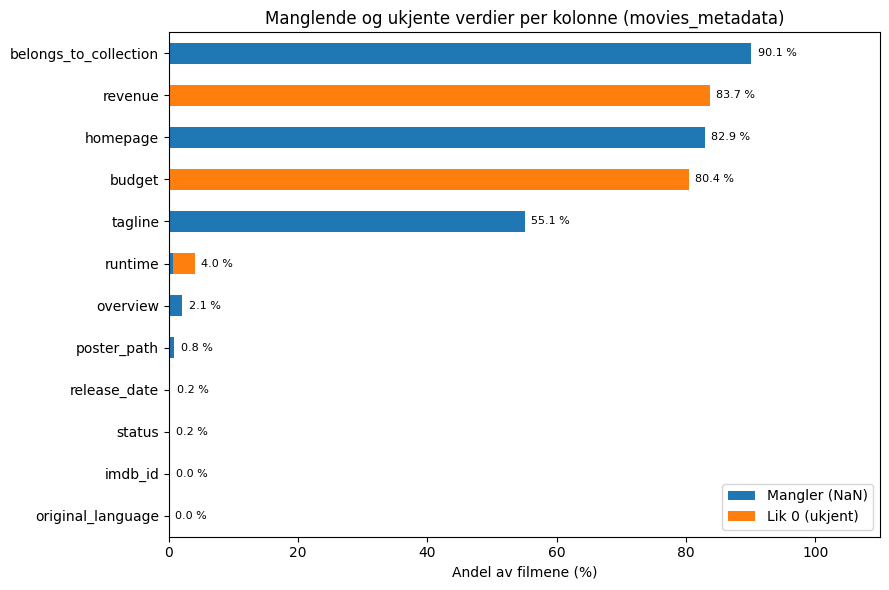

In [32]:
import os
os.makedirs("claude_output/figures", exist_ok=True)

# Andel NaN per kolonne, og andel 0 for feltene der 0 betyr "ukjent"
andel_nan = df_movie_metadata.isna().mean()
andel_null = (df_movie_metadata[["budget", "revenue", "runtime"]] == 0).mean()

tabell = pd.DataFrame({"Mangler (NaN)": andel_nan, "Lik 0 (ukjent)": andel_null}).fillna(0)
tabell = tabell[tabell.sum(axis=1) > 0]
tabell = tabell.loc[tabell.sum(axis=1).sort_values().index].tail(15)

ax = (tabell * 100).plot(kind="barh", stacked=True, figsize=(9, 6), color=["tab:blue", "tab:orange"])
for y, total in enumerate(tabell.sum(axis=1) * 100):
    ax.text(total + 1, y, f"{total:.1f} %", va="center", fontsize=8)
ax.set_xlim(0, 110)
ax.set_xlabel("Andel av filmene (%)")
ax.set_title("Manglende og ukjente verdier per kolonne (movies_metadata)")
plt.tight_layout()
plt.savefig("claude_output/figures/eda_manglende_per_kolonne.png", dpi=200, bbox_inches="tight")
plt.show()

#### Ukjente verdier per tiår

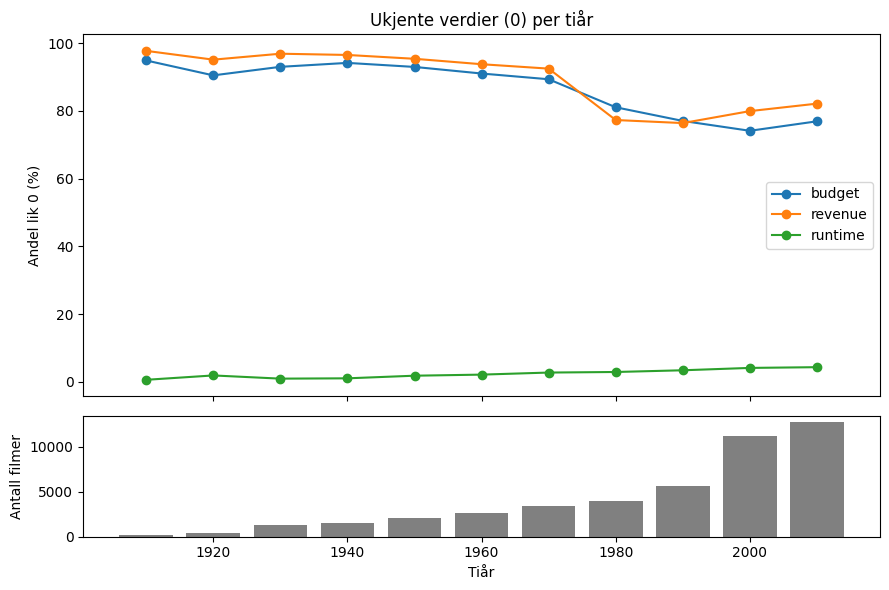

In [33]:
# Er det verre for gamle filmer? Andel 0 per tiår (bare tiår med minst 100 filmer)
df_tiar = df_movie_metadata.dropna(subset=["release_date"]).copy()
df_tiar["tiår"] = df_tiar["release_date"].dt.year // 10 * 10

antall_per_tiar = df_tiar.groupby("tiår").size()
andel_null_tiar = (df_tiar[["budget", "revenue", "runtime"]] == 0).groupby(df_tiar["tiår"]).mean() * 100

gyldige = antall_per_tiar[antall_per_tiar >= 100].index
andel_null_tiar = andel_null_tiar.loc[gyldige]
antall_per_tiar = antall_per_tiar.loc[gyldige]

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9, 6), gridspec_kw={"height_ratios": [3, 1]})
for kolonne in ["budget", "revenue", "runtime"]:
    ax1.plot(andel_null_tiar.index, andel_null_tiar[kolonne], marker="o", label=kolonne)
ax1.set_ylabel("Andel lik 0 (%)")
ax1.set_title("Ukjente verdier (0) per tiår")
ax1.legend()
ax2.bar(antall_per_tiar.index, antall_per_tiar.values, width=8, color="grey")
ax2.set_ylabel("Antall filmer")
ax2.set_xlabel("Tiår")
plt.tight_layout()
plt.savefig("claude_output/figures/eda_null_per_tiar.png", dpi=200, bbox_inches="tight")
plt.show()

#### Antall negative verdier

In [239]:
(df_movie_metadata[analysekolonner] < 0).sum()

budget          0
revenue         0
runtime         0
vote_average    0
vote_count      0
dtype: int64

#### Antall ratings utenfor skalaen 0 til 10

In [240]:
((df_movie_metadata["vote_average"] < 0) | (df_movie_metadata["vote_average"] > 10)).sum()

np.int64(0)

Ingen av de fem tallfeltene har negative verdier, og ingen vote_average ligger utenfor 0–10. Dette er en kontroll av gyldige intervaller, ikke en bekreftelse på at alle verdiene er korrekte.

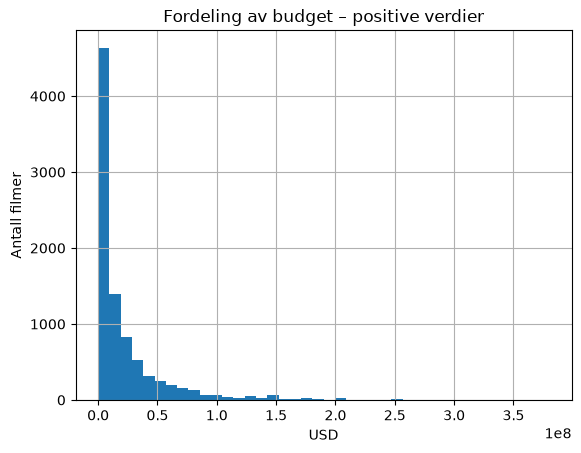

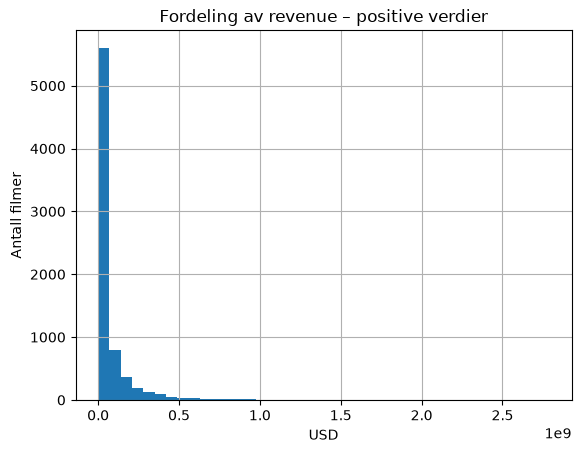

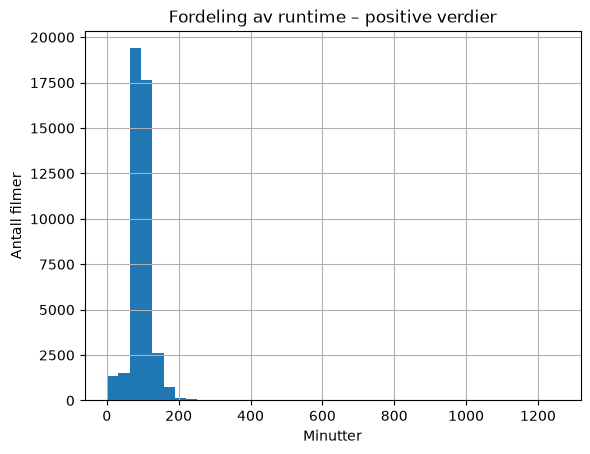

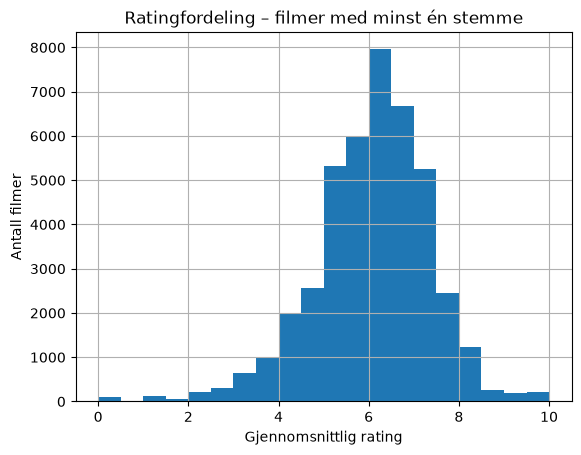

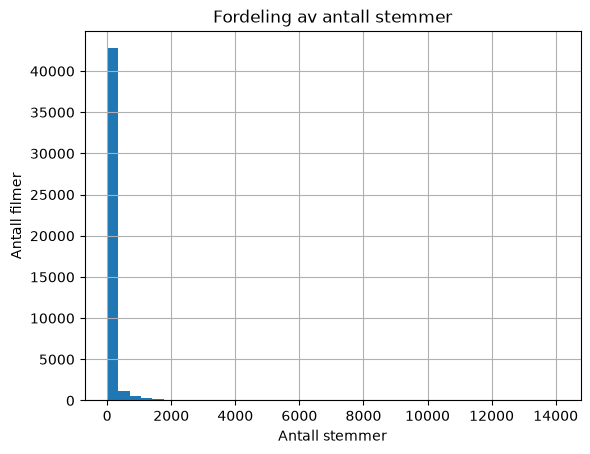

In [241]:
for kolonne in ["budget", "revenue", "runtime"]:
    verdier = df_movie_metadata.loc[df_movie_metadata[kolonne] > 0, kolonne]
    verdier.hist(bins=40)
    plt.title(f"Fordeling av {kolonne} – positive verdier")
    plt.xlabel("Minutter" if kolonne == "runtime" else "USD")
    plt.ylabel("Antall filmer")
    plt.show()

df_movie_metadata.loc[df_movie_metadata["vote_count"] > 0, "vote_average"].hist(bins=20)
plt.title("Ratingfordeling – filmer med minst én stemme")
plt.xlabel("Gjennomsnittlig rating")
plt.ylabel("Antall filmer")
plt.show()

df_movie_metadata["vote_count"].hist(bins=40)
plt.title("Fordeling av antall stemmer")
plt.xlabel("Antall stemmer")
plt.ylabel("Antall filmer")
plt.show()


Histogrammene viser konsentrasjon mot lave beløp og få svært høye verdier for budsjett og inntekt. De tre første figurene viser bare positive verdier, og representerer derfor ikke alle filmer. Runtime har en lang høyrehale, slik at hovedfordelingen blir mindre synlig på hele aksen. Ratingfiguren er filtrert til minst én stemme; vote_count-figuren viser også filmer uten stemmer. Median vote_count er bare 10, så mange ratings bygger på få vurderinger.

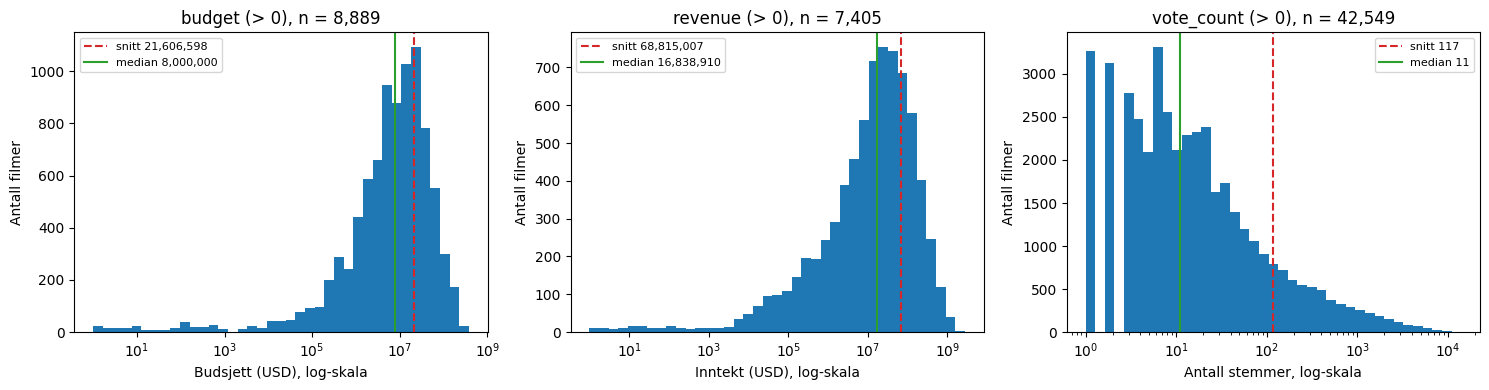

In [37]:
# Samme fordelinger på logaritmisk x-akse. Bare verdier > 0, og bare til figuren (dataene endres ikke).
felt = [("budget", "Budsjett (USD)"), ("revenue", "Inntekt (USD)"), ("vote_count", "Antall stemmer")]

fig, akser = plt.subplots(1, 3, figsize=(15, 4))
for ax, (kolonne, etikett) in zip(akser, felt):
    verdier = df_movie_metadata.loc[df_movie_metadata[kolonne] > 0, kolonne]
    ax.hist(verdier, bins=np.logspace(np.log10(verdier.min()), np.log10(verdier.max()), 40), color="tab:blue")
    ax.axvline(verdier.mean(), color="tab:red", linestyle="--", label=f"snitt {verdier.mean():,.0f}")
    ax.axvline(verdier.median(), color="tab:green", linestyle="-", label=f"median {verdier.median():,.0f}")
    ax.set_xscale("log")
    ax.set_xlabel(etikett + ", log-skala")
    ax.set_ylabel("Antall filmer")
    ax.set_title(f"{kolonne} (> 0), n = {len(verdier):,}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("claude_output/figures/eda_fordelinger_log.png", dpi=200, bbox_inches="tight")
plt.show()

In [242]:
for kolonne in ["budget", "revenue", "runtime", "vote_average", "vote_count"]:
    print(f"Høyeste verdier i {kolonne}:")
    display(df_movie_metadata.nlargest(5, kolonne)[["id", "title", kolonne]] )

# En høy rating bør ses sammen med hvor mange som har stemt.
df_movie_metadata.nlargest(5, "vote_average")[["title", "vote_average", "vote_count"]]

Høyeste verdier i budget:


,id,title,budget
17124,1865,Pirates of the Caribbean: On Stranger Tides,380000000
11827,285,Pirates of the Caribbean: At World's End,300000000
26558,99861,Avengers: Age of Ultron,280000000
11067,1452,Superman Returns,270000000
16130,38757,Tangled,260000000


Høyeste verdier i revenue:


,id,title,revenue
14551,19995,Avatar,"2,787,965,087.00"
26555,140607,Star Wars: The Force Awakens,"2,068,223,624.00"
1639,597,Titanic,"1,845,034,188.00"
17818,24428,The Avengers,"1,519,557,910.00"
25084,135397,Jurassic World,"1,513,528,810.00"


Høyeste verdier i runtime:


...

Høyeste verdier i vote_average:


,id,title,vote_average
186,58372,Reckless,10.00
394,278939,Girl in the Cadillac,10.00
706,73183,"The Haunted World of Edward D. Wood, Jr.",10.00
738,255546,Carmen Miranda: Bananas Is My Business,10.00
1634,64562,Other Voices Other Rooms,10.00


Høyeste verdier i vote_count:


,id,title,vote_count
15480,27205,Inception,"14,075.00"
12481,155,The Dark Knight,"12,269.00"
14551,19995,Avatar,"12,114.00"
17818,24428,The Avengers,"12,000.00"
26564,293660,Deadpool,"11,444.00"


,title,vote_average,vote_count
186,Reckless,10.00,1.00
394,Girl in the Cadillac,10.00,1.00
706,"The Haunted World of Edward D. Wood, Jr.",10.00,1.00
738,Carmen Miranda: Bananas Is My Business,10.00,1.00
1634,Other Voices Other Rooms,10.00,1.00


Høyeste budsjett er 380 millioner USD og høyeste inntekt omtrent 2,79 milliarder USD. Store verdier er ikke alene bevis på feil, og verdiene fjernes derfor ikke bare fordi de er ekstreme. At titlene er kjente bekrefter ikke beløpene. De høyeste beløpene er ikke eksternt verifisert, og beholdes fordi størrelsen alene ikke dokumenterer en feil.

De lengste oppføringene inkluderer Centennial (1 256 minutter), Jazz og Baseball (begge 1 140). [Universal](https://www.universalpicturesathome.com/tv/centennial-the-complete-limited-series) beskriver Centennial som en komplett serie, [PBS](https://www.pbs.org/kenburns/jazz/) beskriver Jazz som en serie i ti deler, og [Ken Burns](https://kenburns.com/films/baseball-2/) beskriver Baseball som en serie i ni deler. Store spilletider kan dermed representere samlede verk fremfor feilregistrering. Kildene bekrefter formatet, ikke nøyaktig alle minuttallene i datasettet; Universal oppgir eksempelvis 20 timer og 54 minutter, mot datasettets 1 256 minutter.

Oppføringene beholdes som en del av det leverte datasettet. Ingen øvre spilletidsgrense innføres. Konsekvensen er at spilletidsanalysen gjelder datasettets oppføringer, som også omfatter serier, og ikke utelukkende enkeltstående kinofilmer.

De fem viste filmene med rating 10 har bare én stemme hver. Det viser hvorfor vote_count-filtrene i Part 2 er viktige, og hvorfor høy rating alene ikke bør tolkes som sterk støtte.

### 11. Konsekvenser av manglende verdier
Sammenligningen bruker én rad per film-ID, med samme utvalg som innsettingskoden. Median vote_count sammenlignes mellom filmer med og uten det aktuelle problemet. Dette undersøker om mangler kan påvirke hvilke filmer som representeres i analysene; det er ikke en test av årsaken til manglene.

In [ ]:
analyse_metadata = df_movie_metadata.sort_values(
    "vote_count", ascending=False, kind="stable"
).drop_duplicates(subset=["id"]).copy()

mangler = {
    "Utgivelsesdato": analyse_metadata["release_date"].isna(),
    "Spilletid (NaN eller 0)": analyse_metadata["runtime"].isna() | analyse_metadata["runtime"].eq(0),
    "Både overview og tagline": analyse_metadata[["overview", "tagline"]].isna().all(axis=1),
    "Originalspråk": analyse_metadata["original_language"].isna()
}

sammenligning = []
for felt, mask in mangler.items():
    sammenligning.append({
        "Felt": felt,
        "Antall berørt": int(mask.sum()),
        "Andel (%)": round(mask.mean() * 100, 2),
        "Median stemmer, berørt": analyse_metadata.loc[mask, "vote_count"].median(),
        "Median stemmer, øvrige": analyse_metadata.loc[~mask, "vote_count"].median()
    })

pd.DataFrame(sammenligning)

Felt,Antall berørt,Andel (%),"Median stemmer, berørt","Median stemmer, øvrige"
Utgivelsesdato,84,0.18,0.0,10.0
Spilletid (NaN eller 0),1815,3.99,2.0,10.0
Både overview og tagline,946,2.08,2.0,10.0
Originalspråk,11,0.02,1.0,10.0


Ukjent dato gjelder 84 filmer (0,18 %), ukjent eller null spilletid 1 815 (3,99 %), begge tekstfeltene 946 (2,08 %) og originalspråk 11 (0,02 %). Median vote_count er henholdsvis 0, 2, 2 og 1 blant de berørte, mot 10 blant de øvrige i alle fire sammenligningene. Manglene forekommer dermed oftere blant filmer med få stemmer, målt ved denne sammenligningen. Det kan gjøre at analyser som krever komplette felt representerer filmer med få stemmer dårligere. Dette viser en sammenheng, ikke at få stemmer forårsaker manglende informasjon.

In [ ]:
uten_tekst = mangler["Både overview og tagline"]
print("Filmer med minst 50 stemmer og begge tekstfeltene manglende:",
      (uten_tekst & analyse_metadata["vote_count"].ge(50)).sum())

Filmer med minst 50 stemmer og begge tekstfeltene manglende: 36


36 filmer oppfyller stemmekravet i oppgave 7, men mangler begge tekstfeltene. De kan ikke gi treff i tekstsøket. Det er ukjent hvor mange som faktisk ville ha matchet noir/neo-noir dersom teksten var tilgjengelig; 36 er derfor ikke antall tapte relevante treff.

#### Følsomhet for svært lange spilletider
En grense på 300 minutter brukes bare som en illustrativ følsomhetskontroll. Det er ingen rensegrense, og ingen rader slettes.

In [ ]:
positiv_runtime = analyse_metadata.loc[analyse_metadata["runtime"] > 0, "runtime"]
print("Oppføringer over 300 minutter:", (positiv_runtime > 300).sum())
print("Median positiv spilletid:", positiv_runtime.median())
print("Median hvis oppføringer over 300 minutter utelates:",
      positiv_runtime[positiv_runtime <= 300].median())

Oppføringer over 300 minutter: 108
Median positiv spilletid: 95.0
Median hvis oppføringer over 300 minutter utelates: 95.0


108 oppføringer har spilletid over 300 minutter. Medianen for positive spilletider er 95 minutter, og 95 minutter når disse utelates. Dette beskriver effekten på den samlede medianen; resultatene per tiår og sjanger kan fortsatt påvirkes annerledes. Oppføringene beholdes, og det legges ingen øvre grense inn i databasen eller spørringene på grunnlag av denne kontrollen.

### 12. Oppsummering og gjenstående vurderinger
**Utført i notebooken:** tre splittede filmer er rekonstruert, fire kolonner er typekonvertert, og 17 identiske ekstrarader er fjernet. Det gjenstår 45 446 rader, inkludert 13 ekstra ID-forekomster. Popularity er satt til gjennomsnittet per film-ID.

**Utført ved innsetting:** én rad per film-ID beholdes, med høyeste registrerte vote_count ved konflikt og første forekomst ved likt stemmetall. Etter dette settes 45 433 unike filmer inn. Listefeltene parses, credits og keywords kobles til filmene, og manglende skalarverdier lagres som null. Rå CSV-filer er urørt.

**Begrunnet håndtering:** ukjent dato, spilletid, språk og tekst fylles ikke med antatte verdier. Filmene beholdes for analyser som kan bruke deres øvrige opplysninger. Null eller ukjent spilletid utelates fra spilletidsberegninger; ukjente datoer og språk utelates fra analyser som krever disse feltene. Dette er regler for spørringene, ikke sletting av hele filmer.

**Gjenstående vurderinger:** ingen øvre grense for spilletid innføres, siden flere ekstreme oppføringer er dokumenterte serier. Nøyaktigheten av alle enkeltbeløp og spilletider er ikke verifisert. Revenue = 0 beholdes i databasen, men utelates fra inntektsberegninger som ukjent verdi; spørringene må følge denne regelen. Tallene i notebooken gjelder de angitte rensestegene og er ikke nødvendigvis identiske med tall etter sammenslåing ved innsetting.

## Credits ##

### .shape ###

In [243]:
df_credits.shape

(45476, 3)

### .head() ###

In [244]:
df_credits.head()

,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


### .dtypes ###

In [245]:
df_credits.dtypes

cast      str
crew      str
id      int64
dtype: object

### .info() ###

In [246]:
df_credits.info()

<class 'pandas.DataFrame'>
RangeIndex: 45476 entries, 0 to 45475
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   cast    45476 non-null  str  
 1   crew    45476 non-null  str  
 2   id      45476 non-null  int64
dtypes: int64(1), str(2)
memory usage: 1.0 MB


### 1. Manglende verdier
Oversikten over datatyper over viser at id allerede er et tallfelt. cast og crew er tekst som inneholder lister.

In [247]:
df_credits.isna().sum()

cast    0
crew    0
id      0
dtype: int64

### 2. Duplikater

In [248]:
print("Helt identiske rader:", df_credits.duplicated().sum())
print("Duplikate film-ID-er:", df_credits["id"].duplicated().sum())

Helt identiske rader: 37
Duplikate film-ID-er: 44


In [249]:
df_credits[df_credits["id"].duplicated(keep=False)].sort_values("id")

,cast,crew,id
25885,"[{'cast_id': 12, 'character': 'The Creature', ...","[{'credit_id': '52fe4380c3a36847f80590dd', 'de...",3057
25950,"[{'cast_id': 12, 'character': 'The Creature', ...","[{'credit_id': '52fe4380c3a36847f80590dd', 'de...",3057
33838,"[{'cast_id': 15, 'character': 'Chuck Barris', ...","[{'credit_id': '52fe43e2c3a36847f80760a9', 'de...",4912
5865,"[{'cast_id': 15, 'character': 'Chuck Barris', ...","[{'credit_id': '52fe43e2c3a36847f80760b5', 'de...",4912
9165,"[{'cast_id': 11, 'character': 'Jef Costello', ...","[{'credit_id': '52fe440ac3a36847f807ee01', 'de...",5511
...,...,...,...
25887,"[{'cast_id': 7, 'character': 'Hollander', 'cre...","[{'credit_id': '52fe4da29251416c9111ce5d', 'de...",199591
24163,"[{'cast_id': 2, 'character': 'Ebba', 'credit_i...","[{'credit_id': '534fd1a80e0a267eb6000e32', 'de...",265189
45275,"[{'cast_id': 2, 'character': 'Ebba', 'credit_i...","[{'credit_id': '534fd1a80e0a267eb6000e32', 'de...",265189
33196,"[{'cast_id': 1, 'character': 'Jenjira', 'credi...","[{'credit_id': '5448c8efc3a3680fb4001582', 'de...",298721


Helt identiske rader kan fjernes uten å miste ulik informasjon. Vi teller deretter ID-duplikatene på nytt.

In [250]:
df_credits = df_credits.drop_duplicates().copy()
print("Gjenstående duplikate ID-er:", df_credits["id"].duplicated().sum())

Gjenstående duplikate ID-er: 7


In [251]:
display(df_credits.loc[df_credits["id"].duplicated(keep=False), ["id", "cast", "crew"]].sort_values("id"))

,id,cast,crew
5865,4912,"[{'cast_id': 15, 'character': 'Chuck Barris', ...","[{'credit_id': '52fe43e2c3a36847f80760b5', 'de..."
33838,4912,"[{'cast_id': 15, 'character': 'Chuck Barris', ...","[{'credit_id': '52fe43e2c3a36847f80760a9', 'de..."
9576,69234,"[{'cast_id': 1, 'character': 'Gerard Carriere'...","[{'credit_id': '5468acec22136e68c9000d53', 'de..."
26638,69234,"[{'cast_id': 1, 'character': 'Gerard Carriere'...","[{'credit_id': '52fe47bfc3a368484e0d77bf', 'de..."
16167,99080,"[{'cast_id': 1004, 'character': 'Luke Oarum', ...","[{'credit_id': '52fe4a269251416c750df623', 'de..."
38882,99080,"[{'cast_id': 1004, 'character': 'Luke Oarum', ...","[{'credit_id': '52fe4a269251416c750df61d', 'de..."
4356,110428,"[{'cast_id': 3, 'character': 'Camille Claudel'...","[{'credit_id': '52fe4ad6c3a36847f81e461b', 'de..."
23533,110428,"[{'cast_id': 3, 'character': 'Camille Claudel'...","[{'credit_id': '577ed5389251416976004432', 'de..."
838,132641,"[{'cast_id': 4, 'character': 'Mihoko Nakagawa'...","[{'credit_id': '52fe4b9ac3a368484e190d25', 'de..."
30013,132641,"[{'cast_id': 4, 'character': 'Mihoko Nakagawa'...","[{'credit_id': '56365ed9925141285701b06e', 'de..."


De sju gjenværende ID-parene har identisk cast og de samme crew-oppføringene i ulik rekkefølge. Første rad per film-ID beholdes derfor uten informasjonstap, slik at samme film ikke telles flere ganger.

In [252]:
df_credits = df_credits.drop_duplicates(subset=["id"], keep="first").copy()
print("Gjenstående duplikate ID-er:", df_credits["id"].duplicated().sum())

Gjenstående duplikate ID-er: 0


### 3. Innholdet i cast og crew
I CSV-filen er cast og crew tekst, selv om innholdet ser ut som lister. literal_eval gjør teksten om til faktiske Python-lister med dictionaries. Da kan antall personer telles, tomme lister oppdages og felter som gender, order og job undersøkes. Dette trengs senere for å finne skuespillere og regissører i Part 2.

Dersom teksten ikke kan parses, stopper cellen med en feilmelding. Ingen opplysninger fylles inn eller slettes ved parsingen.

In [253]:
from ast import literal_eval

df_credits["cast"] = df_credits["cast"].apply(literal_eval)
df_credits["crew"] = df_credits["crew"].apply(literal_eval)

df_credits[["cast", "crew"]].head()

,cast,crew
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de..."
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de..."
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de..."
3,"[{'cast_id': 1, 'character': 'Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de..."
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de..."


In [254]:
print("Tomme cast-lister:", (df_credits["cast"].apply(len) == 0).sum())
print("Tomme crew-lister:", (df_credits["crew"].apply(len) == 0).sum())

Tomme cast-lister: 2414
Tomme crew-lister: 771


### 4. Feltene som brukes i Part 2
Vi lager egne tabeller med én rad per cast- eller crew-oppføring for å undersøke feltene. Dette endrer ikke listene i df_credits.

In [255]:
cast = pd.DataFrame([person for personer in df_credits["cast"] for person in personer])
crew = pd.DataFrame([person for personer in df_credits["crew"] for person in personer])

cast[["id", "name", "gender", "order"]].head()

,id,name,gender,order
0,31,Tom Hanks,2,0
1,12898,Tim Allen,2,1
2,7167,Don Rickles,2,2
3,12899,Jim Varney,2,3
4,12900,Wallace Shawn,2,4


In [256]:
cast[["id", "name", "gender", "order"]].isna().sum()

id        0
name      0
gender    0
order     0
dtype: int64

In [257]:
crew[["id", "name", "job"]].isna().sum()

id      0
name    0
job     0
dtype: int64

#### Kjønn
I dette datasettet er 0 ukjent, 1 kvinne og 2 mann. Ukjent kjønn skal ikke tolkes som mann eller kvinne. Antallene nedenfor gjelder cast-oppføringer, ikke unike personer.

In [258]:
cast["gender"].value_counts(dropna=False).sort_index()

gender
0    223765
1    111724
2    226555
Name: count, dtype: int64

#### Regissører
Vi teller filmer uten en crew-oppføring med job lik Director. Disse kan fortsatt brukes i andre analyser.

In [259]:
har_regissor = df_credits["crew"].apply(
    lambda personer: any(person.get("job") == "Director" for person in personer)
)
print("Filmer uten registrert regissør:", (~har_regissor).sum())

Filmer uten registrert regissør: 887


### 5. Oppsummering av Credits
Credits har ingen NaN-verdier i de tre kolonnene ved innlesing. 37 identiske ekstrarader og 7 ekstra ID-forekomster er fjernet. Det gjenstår 45 432 rader med unik film-ID.

Alle cast- og crew-feltene kunne parses uten feil. Etter fjerning av duplikater har 2414 filmer tom cast-liste og 771 filmer tom crew-liste. Tomme lister betyr at cast eller crew ikke er registrert, ikke at resten av filmopplysningene er ugyldige. Filmene beholdes derfor til analyser der de har nødvendig informasjon. Eksempelvis hindrer tom crew-liste ikke bruk av registrerte skuespillere. Manglende personer fylles ikke inn uten belegg.

Feltene id, name, gender og order i cast og id, name og job i crew har ingen NaN-verdier. Likevel har 223765 cast-oppføringer ukjent kjønn (0), og 887 filmer mangler registrert regissør. Ukjent kjønn utelates fra kjønnsberegningen fordi verdien ikke kan tolkes som kvinne eller mann. Skuespilleroppføringen beholdes til andre analyser, siden ukjent kjønn ikke gjør personens ID eller filmmedvirkning ugyldig.

Filmer uten registrert regissør beholdes fordi cast, inntekt, sjanger og andre opplysninger fortsatt kan brukes. Å slette hele filmen ville også fjernet denne informasjonen fra analyser som ikke krever regissør. Filmene utelates fra regissøranalysene fordi de ikke kan knyttes til en kjent regissør. Regissør imputeres ikke, siden feil tilordning kan påvirke regissørenes filmtall og resultater.

CSV-filen er urørt. Rensing og parsing gjelder bare df_credits i notebooken.

## Keywords ##

### .shape ###

In [260]:
df_keywords.shape

(46419, 2)

### .head() ###

In [261]:
df_keywords.head()

,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


### .dtypes ###

In [262]:
df_keywords.dtypes

id          int64
keywords      str
dtype: object

### .info() ###

In [263]:
df_keywords.info()

<class 'pandas.DataFrame'>
RangeIndex: 46419 entries, 0 to 46418
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   id        46419 non-null  int64
 1   keywords  46419 non-null  str  
dtypes: int64(1), str(1)
memory usage: 725.4 KB


### 1. Manglende verdier og datatyper
Oversikten over viser 46 419 rader og to kolonner. id er allerede et heltall og trenger ikke typekonvertering. keywords er tekst som inneholder lister.

In [264]:
df_keywords.isna().sum()

id          0
keywords    0
dtype: int64

Ingen av kolonnene har NaN. Dette betyr ikke at alle filmer har registrerte keywords: teksten "[]" er en tom liste og telles ikke av isna(). Tomme lister undersøkes etter parsing.

### 2. Duplikater

In [265]:
print("Helt identiske ekstrarader:", df_keywords.duplicated().sum())
print("Ekstra forekomster av film-ID-er:", df_keywords["id"].duplicated().sum())

Helt identiske ekstrarader: 987
Ekstra forekomster av film-ID-er: 987


Det observeres 987 identiske ekstrarader og 987 ekstra ID-forekomster. Identiske rader inneholder samme film-ID og samme keywords og tilfører derfor ingen ny informasjon. De fjernes for å unngå at filmer og keywords telles flere ganger.

In [266]:
df_keywords = df_keywords.drop_duplicates().copy()
print("Gjenstående duplikate ID-er:", df_keywords["id"].duplicated().sum())
print("Antall rader etter rensing:", len(df_keywords))

Gjenstående duplikate ID-er: 0
Antall rader etter rensing: 45432


Etter fjerning av identiske rader gjenstår 45 432 rader og ingen duplikate film-ID-er. I motsetning til Credits er det derfor ingen gjenværende ID-par med ulikt innhold som må sammenlignes.

### 3. Parsing og tomme keyword-lister
literal_eval gjør tekstfeltene om til Python-lister med dictionaries. Da kan antall keywords telles og feltene id og name undersøkes. Uten parsing ville len() telt tegn i teksten fremfor keywords. Parsingen stopper med feilmelding dersom innholdet ikke kan tolkes; ingen opplysninger fylles inn.

In [267]:
df_keywords["keywords"] = df_keywords["keywords"].apply(literal_eval)
df_keywords.head(3)

,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."


#### Keyword-navn som bare inneholder mellomrom
Fire oppføringer har keyword-ID 13091, men navnet består bare av et mellomrom. Dette fanges ikke opp av isna(). Bare disse tomme keyword-oppføringene fjernes, siden de ikke beskriver noe tema. Filmene og øvrige keywords beholdes.

In [268]:
print("Tomme keyword-navn før rensing:", sum(1 for liste in df_keywords["keywords"] for keyword in liste if not keyword["name"].strip()))

df_keywords["keywords"] = df_keywords["keywords"].apply(
    lambda liste: [keyword for keyword in liste if keyword["name"].strip()]
)

Tomme keyword-navn før rensing: 4


In [269]:
antall_keywords = df_keywords["keywords"].apply(len)
print("Filmer uten registrerte keywords:", (antall_keywords == 0).sum())
print("Andel uten registrerte keywords (%):", round((antall_keywords == 0).mean() * 100, 2))

Filmer uten registrerte keywords: 14340
Andel uten registrerte keywords (%): 31.56


Alle feltene kunne parses uten feil. Det observeres 14 340 tomme keyword-lister, omtrent 31,56 % av filmene. Tom liste betyr at keywords ikke er registrert her, ikke at filmen mangler temaer. Filmene beholdes fordi øvrige filmopplysninger fortsatt kan brukes. Keywords imputeres ikke, siden antatte temaer ville tilført informasjon uten belegg. Ved en eventuell keyword-analyse bidrar bare registrerte keywords.

### 4. Innhold og fordeling
En egen tabell med én rad per keyword-oppføring brukes til å kontrollere feltene. Dette endrer ikke listene i df_keywords.

In [270]:
keywords = pd.DataFrame([keyword for liste in df_keywords["keywords"] for keyword in liste])
keywords[["id", "name"]].isna().sum()

id      0
name    0
dtype: int64

In [271]:
print("Tomme keyword-navn:", keywords["name"].str.strip().eq("").sum())
print("Ugyldige film-ID-er:", ((df_keywords["id"] <= 0) | df_keywords["id"].isna()).sum())

Tomme keyword-navn: 0
Ugyldige film-ID-er: 0


Etter fjerning av de fire tomme keyword-oppføringene mangler ingen gjenværende oppføringer id eller name. Kontrollen finner heller ingen tomme navn eller ugyldige film-ID-er. Film-ID viser til filmen; id inni keyword-listen viser til et keyword. Disse ID-ene har forskjellige roller.

In [272]:
antall_keywords.describe().round(2)

count   45,432.00
mean         3.45
std          4.69
min          0.00
25%          0.00
50%          2.00
75%          5.00
max        149.00
Name: keywords, dtype: float64

Medianen er 2 keywords per film, gjennomsnittet er omtrent 3,45 og maksimum er 149. Gjennomsnittet ligger over medianen, noe som viser at filmer med mange keywords trekker det opp. Tomme lister er inkludert i disse tallene. 149 keywords undersøkes med et eksempel før det vurderes som feil.

In [273]:
flest_keywords = df_keywords.loc[antall_keywords.idxmax()]
print("Film-ID med flest keywords:", flest_keywords["id"])
print("Antall keywords:", len(flest_keywords["keywords"]))
pd.DataFrame(flest_keywords["keywords"])[["id", "name"]].head(5)

Film-ID med flest keywords: 23160
Antall keywords: 149


,id,name
0,246,dancing
1,255,male nudity
2,291,circus
3,305,moon
4,472,bathroom


In [274]:
keywords["name"].value_counts().head(5)

name
woman director      3039
independent film    1914
murder              1285
based on novel       822
musical              726
Name: count, dtype: int64

Blant de vanligste registrerte keyword-navnene er woman director (3 039 oppføringer), independent film (1 914) og murder (1 285). Dette beskriver merkingen i datasettet, ikke nødvendigvis hele filmenes innhold. Høyt antall keywords er ikke alene grunnlag for å slette en film; oppføringen med 149 beholdes foreløpig. Eksempelvisningen er begrenset til fem keywords, og bekrefter derfor ikke at alle 149 er korrekte.

### 5. Oppsummering av Keywords
Keywords hadde 46 419 rader uten NaN. 987 identiske ekstrarader er fjernet, slik at 45 432 unike film-ID-er gjenstår. Ingen ulike ID-duplikater måtte slås sammen.

Tekstfeltene er parset til lister slik at keyword-innhold kan undersøkes. 14 340 filmer har tomme lister. Disse beholdes fordi manglende keywords ikke gjør øvrige filmopplysninger ugyldige. Ingen keywords imputeres.

Medianen er 2 keywords per film, og maksimum er 149. Store antall slettes ikke uten dokumentasjon på feil. Feltene id og name har ingen mangler eller tomme navn.

Fire keyword-oppføringer med navn som bare inneholdt mellomrom er fjernet. Filmene er beholdt.

Keywords må kobles til metadata på film-ID ved innsetting. Likhet mellom ID-settene på tvers av filene er ikke kontrollert i denne delen. CSV-filen er urørt; endringene gjelder bare DataFramen i notebooken.

# Del B: Links og Ratings #

## Links_small ##

### .shape ###

In [6]:
df_links_small.shape

(9125, 3)

### .head() ###

In [7]:
df_links_small.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### .dtypes ###

In [8]:
df_links_small.dtypes

movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

### .info() ###

In [9]:
df_links_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9125 entries, 0 to 9124
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  9125 non-null   int64  
 1   imdbId   9125 non-null   int64  
 2   tmdbId   9112 non-null   float64
dtypes: float64(1), int64(2)
memory usage: 214.0 KB


**Observasjon:** links_small har 9 125 filmer og tre ID-kolonner. `movieId` er MovieLens sin ID, `imdbId` er IMDb-ID uten «tt»-prefiks, og `tmdbId` er ID-en som brukes i `movies_metadata`, `credits` og `keywords`. `tmdbId` har bare 9 112 non-null-verdier og er derfor `float64`. Filen fungerer som en koblingstabell mellom ratings og resten av datasettet.

## Links ##

### .shape ###

In [10]:
df_links.shape

(45843, 3)

### .head() ###

In [11]:
df_links.head()

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### .dtypes ###

In [12]:
df_links.dtypes

movieId      int64
imdbId       int64
tmdbId     float64
dtype: object

### .info() ###

In [13]:
df_links.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45843 entries, 0 to 45842
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   movieId  45843 non-null  int64  
 1   imdbId   45843 non-null  int64  
 2   tmdbId   45624 non-null  float64
dtypes: float64(1), int64(2)
memory usage: 1.0 MB


**Observasjon:** links har 45 843 filmer, omtrent fem ganger så mange som links_small, med de samme tre kolonnene og datatypene. `tmdbId` har 45 624 non-null-verdier. Antallet ligger nær de 45 463 filmene i movies_metadata etter reparasjon, men det betyr ikke nødvendigvis at alle kan kobles (se siste seksjon).

## Ratings_small ##

### .shape ###

In [14]:
df_ratings_small.shape

(100004, 4)

### .head() ###

In [15]:
df_ratings_small.head()

,userId,movieId,rating,timestamp
0,1,31,2.5,1260759144
1,1,1029,3.0,1260759179
2,1,1061,3.0,1260759182
3,1,1129,2.0,1260759185
4,1,1172,4.0,1260759205


### .dtypes ###

In [16]:
df_ratings_small.dtypes

userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

### .info() ###

In [17]:
df_ratings_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100004 entries, 0 to 100003
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100004 non-null  int64  
 1   movieId    100004 non-null  int64  
 2   rating     100004 non-null  float64
 3   timestamp  100004 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


**Observasjon:** ratings_small har 100 004 ratings med fire kolonner. `rating` er `float64` fordi skalaen har halve steg, og `timestamp` er lagret som heltall (Unix-tid), ikke som dato. Ingen kolonner har manglende verdier ifølge `.info()`.

## Ratings ##

### .shape ###

In [18]:
df_ratings.shape

(26024289, 4)

### .head() ###

In [19]:
df_ratings.head()

,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


### .dtypes ###

In [20]:
df_ratings.dtypes

userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object

### .info() ###

In [21]:
df_ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26024289 entries, 0 to 26024288
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 794.2 MB


**Observasjon:** ratings har 26 024 289 ratings og bruker omtrent 794 MB minne i pandas, altså rundt 260 ganger så mange rader som ratings_small. Kolonnene og datatypene er de samme. Størrelsen har betydning for Part 1: tabellen bør settes inn i batcher og ikke som ett stort kall. `.info()` viser ikke non-null-antall for så store tabeller, så manglende verdier sjekkes eksplisitt nedenfor.

-------------------------------------------------

# Videre analyse av links og ratings #

## Links og links_small ##

### 1. Manglende verdier

In [22]:
print("links_small:\n", df_links_small.isna().sum(), "\n")
print("links:\n", df_links.isna().sum())

links_small:
 movieId     0
imdbId      0
tmdbId     13
dtype: int64 

links:
 movieId      0
imdbId       0
tmdbId     219
dtype: int64


Bare `tmdbId` mangler verdier: 13 av 9 125 rader i links_small og 219 av 45 843 rader i links (omtrent 0,5 %). `movieId` og `imdbId` er komplette. De manglende verdiene er grunnen til at `tmdbId` er `float64`: NaN finnes ikke for vanlige heltall i pandas, så hele kolonnen tvinges over til flyttall.

Filmer uten `tmdbId` kan ikke kobles til `movies_metadata`, `credits` eller `keywords`. Radene beholdes likevel, fordi `movieId` fortsatt kobler dem til ratings, og en manglende ekstern ID gjør ikke ratingene ugyldige. `tmdbId` imputeres ikke: en gjettet ID ville koblet ratings til feil film. Før kobling mot `movies_metadata` bør kolonnen gjøres om til heltall (f.eks. `Int64`, som tåler NaN), slik at `862.0` sammenlignes som `862`.

### 2. Duplikater

In [23]:
for navn, df in [("links_small", df_links_small), ("links", df_links)]:
    print(navn)
    print("  Duplikate movieId:", df["movieId"].duplicated().sum())
    print("  Duplikate imdbId: ", df["imdbId"].duplicated().sum())
    print("  Duplikate tmdbId: ", df["tmdbId"].dropna().duplicated().sum())

links_small
  Duplikate movieId: 0
  Duplikate imdbId:  0
  Duplikate tmdbId:  0
links
  Duplikate movieId: 0
  Duplikate imdbId:  0
  Duplikate tmdbId:  30


In [24]:
# Ser på noen av radene der flere movieId peker på samme tmdbId
tmdb_dup = df_links[df_links["tmdbId"].notna() & df_links["tmdbId"].duplicated(keep=False)]
tmdb_dup.sort_values("tmdbId").head(6)

,movieId,imdbId,tmdbId
5905,6003,290538,4912.0
34144,144606,270288,4912.0
9215,27136,165303,5511.0
7388,7587,62229,5511.0
45197,174533,235679,10991.0
4148,4241,266860,10991.0


`movieId` og `imdbId` er unike i begge filene, så de kan brukes som nøkler. I links peker 30 `tmdbId` på mer enn én `movieId`. Eksempelet viser blant annet at `tmdbId` 4912 er koblet til både `movieId` 6003 og 144606, med ulike `imdbId`. To MovieLens-filmer peker altså på samme TMDB-film, og det er uklart om det er feil i koblingen eller to oppføringer av samme film.

Koblingen links → movies_metadata er derfor ikke helt én-til-én, og ratings for én TMDB-film kan være spredt på flere `movieId`. Radene slettes ikke, fordi det ikke er mulig å avgjøre ut fra links alene hvilken kobling som er riktig. Ved innsetting beholdes alle ratingene med opprinnelig movieId og tilhørende tmdbId. Flere movieId kan dermed referere til samme filmdokument, uten at vurderinger slettes eller gjennomsnittsberegnes. Analyser som teller unike filmer eller sjangre må ta hensyn til felles tmdbId; ratingantall og varians teller de opprinnelige vurderingene. Antall berørte koblinger alene sier ikke hvor stor effekten er på analysene.

### 3. Er links_small et delsett av links?

In [25]:
mangler_i_links = ~df_links_small["movieId"].isin(df_links["movieId"])
print("movieId i links_small som ikke finnes i links:", mangler_i_links.sum())
df_links_small[mangler_i_links]

movieId i links_small som ikke finnes i links: 10


,movieId,imdbId,tmdbId
5173,7502,185906,191903.0
7527,77658,81846,205300.0
8045,94466,2085059,NaN
8505,108548,898266,NaN
8507,108583,72500,NaN
8520,108979,213338,314040.0
9062,150856,5189670,374454.0
9118,162376,4574334,410612.0
9123,164977,27660,137608.0
9124,164979,3447228,410803.0


Nesten, men ikke helt: 10 filmer i links_small finnes ikke i links. Tre av dem mangler også `tmdbId`. Small-versjonen er altså ikke et rent utsnitt av den fulle, og de to filene kan ikke behandles som samme datasett i ulik størrelse.

Dette betyr at valget av links-fil må følge valget av ratings-fil: ratings_small bør kobles via links_small, og ratings via links (se også koblingen nederst).

### 4. Oppsummering av Links
links_small har 9 125 og links 45 843 filmer. `movieId` og `imdbId` er unike og komplette i begge. Bare `tmdbId` mangler verdier (13 og 219), og radene beholdes fordi de fortsatt kobler ratings til `movieId`. Ingen ID-er imputeres.

I links peker 30 `tmdbId` på flere `movieId`. Alle opprinnelige ratings og movieId beholdes ved innsetting, med referanse til samme tmdbId der koblingen finnes. links_small er ikke et rent delsett av links (10 filmer mangler), så links-filen må velges i samme størrelse som ratings-filen. `tmdbId` lagres som heltall ved innsetting, eller null når kobling til et filmdokument mangler.

## Ratings og ratings_small ##

### 1. Manglende verdier og duplikater

In [26]:
for navn, df in [("ratings_small", df_ratings_small), ("ratings", df_ratings)]:
    print(navn)
    print("  Manglende verdier totalt:  ", df.isna().sum().sum())
    print("  Helt identiske rader:      ", df.duplicated().sum())
    print("  Duplikate (userId, movieId):", df.duplicated(subset=["userId", "movieId"]).sum())

ratings_small
  Manglende verdier totalt:   0
  Helt identiske rader:       0
  Duplikate (userId, movieId): 0
ratings
  Manglende verdier totalt:   0
  Helt identiske rader:       0
  Duplikate (userId, movieId): 0


Ingen manglende verdier, ingen helt identiske rader og ingen duplikate `(userId, movieId)`-par i noen av filene. Hver bruker har altså vurdert hver film maks én gang, så `(userId, movieId)` fungerer som en naturlig sammensatt nøkkel. Ingen rader trenger å fjernes eller slås sammen.

`.info()` for ratings viste ikke non-null-antall fordi tabellen er stor (pandas hopper over tellingen for over 1,69 mill. rader som standard). Derfor er `isna()` brukt her for å bekrefte at det ikke mangler noe.

### 2. Gyldige ratingverdier

In [27]:
print("ratings_small:", sorted(df_ratings_small["rating"].unique().tolist()))
print("ratings:      ", sorted(df_ratings["rating"].unique().tolist()))

ratings_small: [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
ratings:       [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]


Skalaen er 0,5 til 5 i halve steg, med de samme ti verdiene i begge filene. Ingen verdier ligger utenfor skalaen, og det finnes ingen 0-ratinger som kunne vært en kode for «mangler». Ratingene kan derfor brukes direkte uten filtrering.

Merk at skalaen er en annen enn `vote_average` i movies_metadata (0 til 10). Ratings fra de to kildene kan ikke sammenlignes direkte uten å skalere den ene.

### 3. Tidsstempel

`timestamp` er Unix-tid (sekunder siden 1970). Vi konverterer til datetime for å se hvilken periode dataene dekker.

In [28]:
for df in [df_ratings_small, df_ratings]:
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="s")

print("ratings_small:", df_ratings_small["timestamp"].min(), "til", df_ratings_small["timestamp"].max())
print("ratings:      ", df_ratings["timestamp"].min(), "til", df_ratings["timestamp"].max())

ratings_small: 1995-01-09 11:46:49 til 2016-10-16 17:57:24
ratings:       1995-01-09 11:46:44 til 2017-08-04 06:57:50


ratings_small dekker januar 1995 til oktober 2016, og ratings dekker januar 1995 til august 2017. Begge starter samme dag, noe som tyder på at de kommer fra samme MovieLens-kilde, men den fulle filen er nyere. Ingen tidsstempler ligger i framtiden eller rundt 1970 (som ville tydet på 0 eller manglende verdi), så det er ingen åpenbart feil verdier.

Konverteringen er gjort direkte i DataFramene, så `timestamp` er `datetime64` i resten av notebooken. Ved innsetting i MongoDB bør feltet lagres som dato og ikke som heltall, slik at det kan filtreres på tidsperioder.

### 4. Fordeling av ratings

In [29]:
df_ratings["rating"].describe()

count    2.602429e+07
mean     3.528090e+00
std      1.065443e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

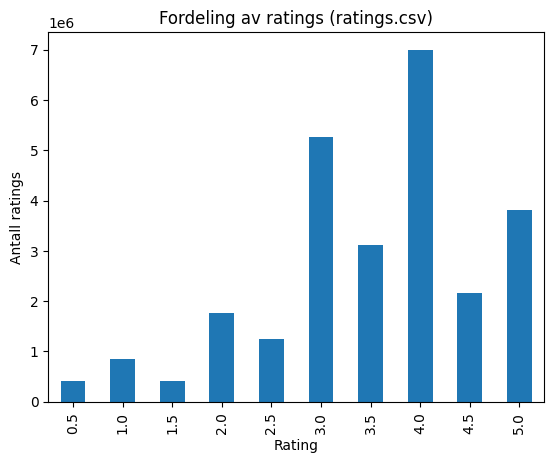

In [30]:
df_ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Fordeling av ratings (ratings.csv)")
plt.xlabel("Rating")
plt.ylabel("Antall ratings")
plt.show()

Gjennomsnittet er 3,53 og medianen 3,5, med standardavvik 1,07. Halvparten av alle ratings ligger mellom 3 og 4. Fordelingen er venstreskjev: 4 er vanligst, og lave ratings er sjeldne. Hele tall brukes oftere enn halve. Dette er en observert frekvensforskjell; årsaken kan ikke fastslås fra denne fordelingen alene.

En rating på 3 ligger under både datasettets gjennomsnitt og median. Fordelingen alene sier ikke noe sikkert om hva den enkelte bruker mener med denne verdien. Ingen verdier fjernes; fordelingen beskriver brukeratferd, ikke feil i dataene.

### 5. Antall ratings per bruker og per film

In [31]:
per_bruker = df_ratings.groupby("userId").size()
per_film = df_ratings.groupby("movieId").size()

print("Antall brukere:", per_bruker.shape[0])
print("Antall filmer: ", per_film.shape[0])
pd.DataFrame({"per bruker": per_bruker.describe(), "per film": per_film.describe()})

Antall brukere: 270896
Antall filmer:  45115


,per bruker,per film
count,270896.000000,45115.000000
mean,96.067454,576.843378
std,205.719606,3037.380582
min,1.000000,1.000000
25%,15.000000,2.000000
50%,30.000000,8.000000
75%,93.000000,69.000000
max,18276.000000,91921.000000


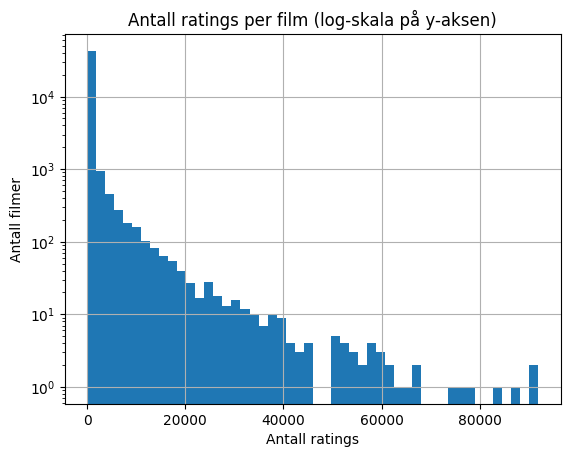

In [32]:
per_film.hist(bins=50, log=True)
plt.title("Antall ratings per film (log-skala på y-aksen)")
plt.xlabel("Antall ratings")
plt.ylabel("Antall filmer")
plt.show()

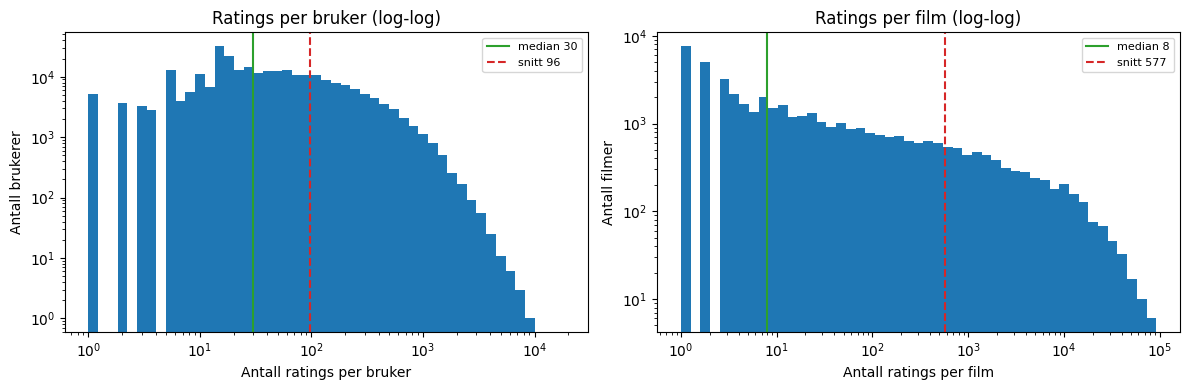

In [98]:
import os
os.makedirs("claude_output/figures", exist_ok=True)

# Lang hale: noen få brukere og filmer står for veldig mange ratings
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, serie, navn in [(ax1, per_bruker, "bruker"), (ax2, per_film, "film")]:
    ax.hist(serie, bins=np.logspace(0, np.log10(serie.max()), 50), color="tab:blue")
    ax.axvline(serie.median(), color="tab:green", label=f"median {serie.median():,.0f}")
    ax.axvline(serie.mean(), color="tab:red", linestyle="--", label=f"snitt {serie.mean():,.0f}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(f"Antall ratings per {navn}")
    ax.set_ylabel(f"Antall {navn}er" if navn == "bruker" else "Antall filmer")
    ax.set_title(f"Ratings per {navn} (log-log)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("claude_output/figures/eda_ratings_per_bruker_film.png", dpi=200, bbox_inches="tight")
plt.show()

Det er 270 896 brukere og 45 115 filmer i ratings. Begge fordelingene er svært høyreskjeve: gjennomsnittet ligger langt over medianen.

- **Per film:** medianen er bare 8 ratings, og en fjerdedel av filmene har 2 eller færre. De mest populære har over 90 000 (maks 91 921). Gjennomsnittet på 577 trekkes opp av noen få svært populære filmer.
- **Per bruker:** medianen er 30 ratings og gjennomsnittet 96. Den mest aktive brukeren har 18 276 ratings, noe som er uvanlig mye for én person.

En gjennomsnittsrating for en film med få stemmer er lite pålitelig: én enkelt 5-er gir toppscore. I analysene bør vi derfor sette en nedre grense for antall ratings før filmer rangeres. Ekstremt aktive brukere slettes ikke, fordi det ikke er dokumentert at ratingene deres er feil, men de kan påvirke resultater som teller per bruker.

### 6. ratings_small vs. ratings

In [33]:
print("ratings_small: brukere =", df_ratings_small["userId"].nunique(), ", filmer =", df_ratings_small["movieId"].nunique())
print("ratings:       brukere =", df_ratings["userId"].nunique(), ", filmer =", df_ratings["movieId"].nunique())

felles = df_ratings_small.merge(df_ratings, on=["userId", "movieId"])
print("Par (userId, movieId) fra ratings_small som også finnes i ratings:", len(felles), "av", len(df_ratings_small))

ratings_small: brukere = 671 , filmer = 9066
ratings:       brukere = 270896 , filmer = 45115
Par (userId, movieId) fra ratings_small som også finnes i ratings: 6361 av 100004


ratings_small har 671 brukere og 9 066 filmer, mot 270 896 brukere og 45 115 filmer i ratings. Bare 6 361 av 100 004 par (omtrent 6 %) fra ratings_small finnes igjen i ratings. Hvis ratings_small var et uendret radutvalg med samme bruker-ID-system, skulle alle parene gått igjen.

ratings_small er derfor **ikke et direkte radutvalg med uendrede ID-er** av den fulle filen. Overlappskontrollen alene avgjør ikke om de underliggende brukervurderingene kan stamme fra samme kilde med omkodede ID-er. `userId` betyr trolig ikke samme person i de to filene, og de få treffene kan være tilfeldige. De to filene må ikke blandes eller slås sammen, og analysene må bruke én av dem konsekvent.

### 7. Oppsummering av Ratings
ratings_small har 100 004 og ratings 26 024 289 rader. Ingen av filene har manglende verdier, duplikater eller ratings utenfor skalaen 0,5 til 5. `(userId, movieId)` er unik og kan brukes som nøkkel. `timestamp` er konvertert fra Unix-tid til dato og dekker 1995 til 2016/2017.

Fordelingen av ratings er venstreskjev med gjennomsnitt 3,53. Antall ratings per film og per bruker er svært skjevt, og medianfilmen har bare 8 ratings. I rangeringer bør det derfor brukes en nedre grense for antall ratings. Ingen rader er fjernet.

ratings_small er ikke et direkte radutvalg med uendrede ID-er av ratings, og de to filene må ikke blandes.

## Kobling mellom datasettene ##

ratings → links via `movieId`, og links → movies_metadata via `tmdbId` = `id`. Vi sjekker hvor mye som faktisk lar seg koble.

In [34]:
print("movieId i ratings som finnes i links:            ", df_ratings["movieId"].isin(df_links["movieId"]).mean())
print("movieId i ratings_small som finnes i links_small:", df_ratings_small["movieId"].isin(df_links_small["movieId"]).mean())
print("movieId i ratings_small som finnes i links:      ", df_ratings_small["movieId"].isin(df_links["movieId"]).mean())

movieId i ratings som finnes i links:             1.0
movieId i ratings_small som finnes i links_small: 1.0
movieId i ratings_small som finnes i links:       0.999540018399264


In [35]:
# Leser bare id-kolonnen fra movies_metadata. Feilformaterte id-er (datoer) blir NaN.
metadata_id = pd.to_numeric(pd.read_csv("data/movies_metadata.csv", usecols=["id"])["id"], errors="coerce")

tmdb = df_links["tmdbId"].dropna()
print("tmdbId i links som finnes i movies_metadata:", tmdb.isin(metadata_id).mean())
print("Antall som ikke finnes:", (~tmdb.isin(metadata_id)).sum())

tmdbId i links som finnes i movies_metadata: 0.996471155532176
Antall som ikke finnes: 161


Koblingen er nesten fullstendig:

- Alle `movieId` i ratings finnes i links, og alle `movieId` i ratings_small finnes i links_small.
- Mot den fulle links-filen mangler 46 ratings i ratings_small (de 10 filmene fra seksjon 3). Det bekrefter at ratings_small hører sammen med links_small.
- Av 45 624 `tmdbId` i links finnes 161 (omtrent 0,35 %) ikke i movies_metadata. Ratings på disse filmene kan ikke knyttes til metadata, så de mister tittel, sjanger osv. ved innsetting.
- links har 45 843 filmer, mens ratings bare har ratings for 45 115. Rundt 730 filmer i links har altså ingen ratings.

Ratings uten metadata beholdes, fordi ratingen i seg selv er gyldig, men de vil falle bort i analyser som krever tittel eller sjanger. Merk at sjekken mot movies_metadata leser `id` direkte fra rå CSV, med feilformaterte ID-er gjort om til NaN. Etter reparasjonen i eda_tahir kan tallet derfor bli litt annerledes.

## Oppsummering og valg ved innsetting
Ingen ratings-rader er slettet eller imputert. Kontrollen fant ingen duplikate (userId, movieId)-par eller ratings utenfor skalaen. Manglende TMDB-koblinger beholdes som ukjente referanser.

1. **Datasett:** innsettingen bruker ratings.csv sammen med links.csv. Småfilene er et separat testalternativ og blandes ikke med fullfilene.
2. **Flere movieId per tmdbId:** alle opprinnelige ratings beholdes. movieId lagres sammen med tmdbId, slik at flere MovieLens-ID-er kan peke til samme film uten at vurderingene slås sammen. Unike filmer må telles på TMDB-ID ved behov.
3. **Filmer uten metadata:** ratingen beholdes med opprinnelig movieId og tmdbId = null dersom filmdokumentet ikke finnes. Ved innsetting av fullfilen gjaldt dette 42 707 ratings. De kan brukes til ratingantall og varians, men ikke bidra med ukjent sjanger i sjangerberegningen.
4. **Datatyper og størrelse:** TMDB-referanser lagres som heltall eller null, og timestamp som dato i UTC. Ratings leses og settes inn i batcher på opptil 10 000.
5. **Få vurderinger:** antall stemmer må tas med i tolkningen av gjennomsnittsrating. Eventuelle ekstra filtre utover oppgavens krav må begrunnes eksplisitt.

Notebooken viser utforskningen av råfilene. Innsettingsvalgene ovenfor er implementert i insert_data.py; råfilene er ikke endret.